# Function 8 - Week 4: observation review

Review what the completed experiments have shown before using a model to choose
the next query. This notebook examines measured inputs and outputs; fitted
relationships, predictive uncertainty and candidate selection belong in
[model review and next query](model_predictions.ipynb).

The independent Week 4 `observations.csv` contains **40 initial observations
and three returned queries**, including the Week 3 return received on
**14 October 2026**. Larger signed outputs are better. The eight input settings
each lie in `[0, 1)`. Earlier weekly notebooks remain the record of the evidence
and reasoning available at those times.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_8/Week_04 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The three later rounds
each contain one deliberately selected query.

In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 8.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 40, 1: 1, 2: 1, 3: 1}:
    raise ValueError("This review expects the fixed Week 4 snapshot through round 3.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 4"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,8
1,Initial observations,40
2,Returned queries,3
3,Total observations,43
4,"Queries available, including Week 4",10


Weekly queries used: 3/13


## 2. Place the latest return among the observed outputs

The latest output is **8.798303**, ranked **11/43 (1 = highest output)**.
It is below both earlier returned queries and does not improve the incumbent
of **9.598482**, which still comes from the initial batch. Rounds 1 and 2 are
the second- and third-highest observations; round 3 is outside the top-five close-up.

In [3]:
print(output_review["report"])

Latest recorded submission: round 3 (1 new output).
Compared with 42 earlier observations (43 outputs in total).
Earlier output range: [5.59219338954, 9.59848200257].

round-03: y = 8.7983029 (positive); rank 11/43 (1 = highest output).
Inputs: x1 = 0, x2 = 0, x3 = 0, x4 = 0.999999, x5 = 0.999999, x6 = 0.999999, x7 = 0, x8 = 0
Within the earlier output range.


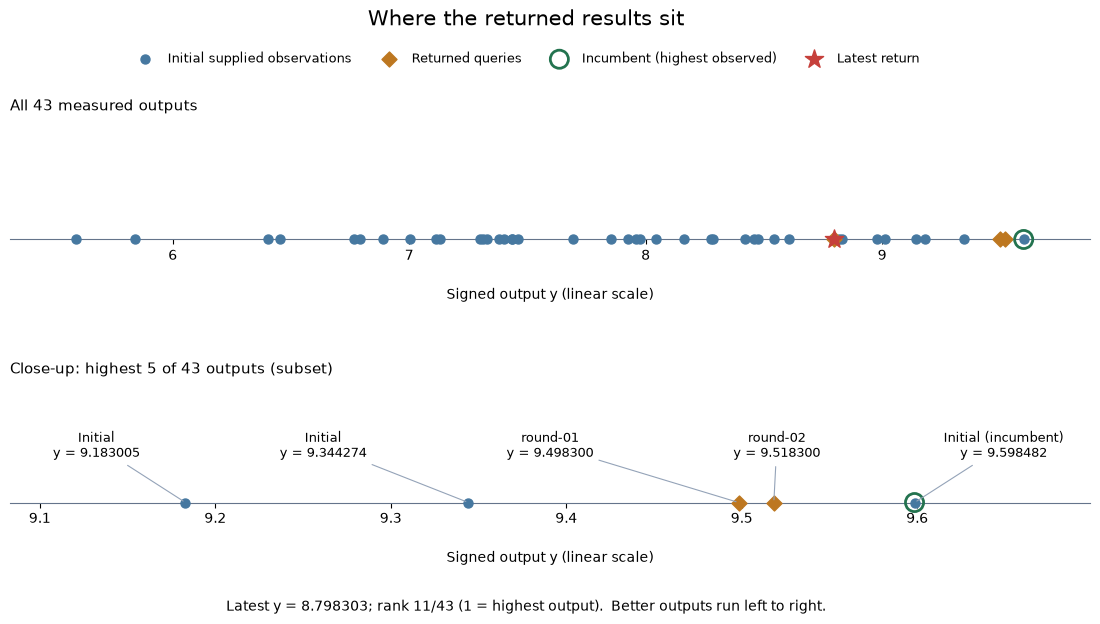

In [4]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 43 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. The later queries were
chosen using earlier evidence, so this view does not estimate the distribution
of scores throughout the input domain or establish the unknown global maximum.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in the
function's original output units.

In [5]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,9.598482,—
Round 1,9.498300,9.598482,-0.100182
Round 2,9.518300,9.598482,-0.080182
Round 3,8.798303,9.598482,-0.800179


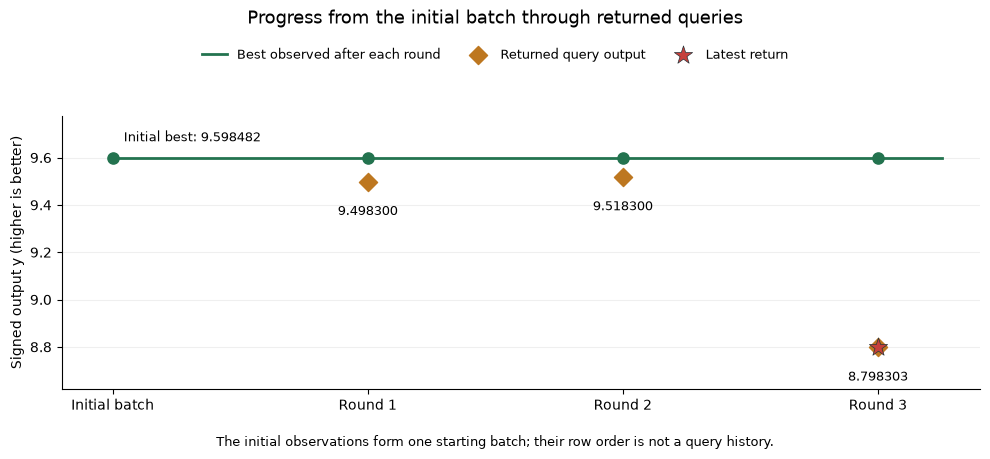

In [6]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

None of the three returned queries has improved the initial best of
**9.598482**, so the best-so-far line is flat throughout. Round 2 slightly
improved on round 1's return, but round 3 is lower than both. Its output is
**0.800179 output units** below the incumbent; total incumbent improvement is **zero**.

This records no optimisation gain so far. It is a reason to scrutinise the next
proposal and the model's errors, not evidence that the unknown function is flat
or that no better input exists. Three selected queries cover very little of an
eight-dimensional domain, and no alternative query sequence was evaluated.

## 4. Examine the strongest input combinations

Keep all eight coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

The figure rounds input labels to three decimals; use the table for six-decimal settings.

In [7]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y
observation_id,,,,,,,,,,,
initial-015,1,0,0.056447,0.065956,0.022929,0.038786,0.403935,0.801055,0.488307,0.893085,9.598482
round-02,2,2,0.000000,0.000000,0.000000,0.000000,0.999999,0.000000,0.000000,0.999999,9.518300
round-01,3,1,0.000000,0.000000,0.000000,0.000000,0.999999,0.000000,0.000000,0.000000,9.498300
initial-027,4,0,0.192640,0.630677,0.416796,0.490529,0.796086,0.654567,0.276241,0.295518,9.344274
initial-040,5,0,0.481245,0.102461,0.219486,0.677322,0.247509,0.244341,0.163825,0.715962,9.183005


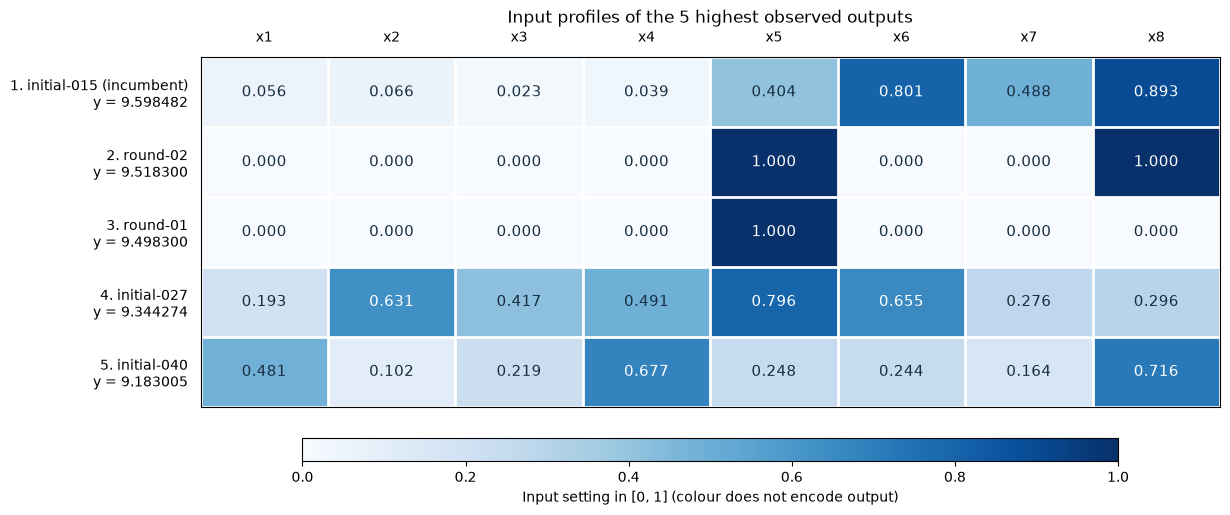

In [8]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

The incumbent is **initial-015**. Rounds 1 and 2 are the next strongest
observations and share their first seven input settings, changing x8 from
**0.000000** to **0.999999**. That measured pair differs by **0.020000 output
units**, but both results remain below the incumbent.

Round 3 is outside these five strongest combinations. The incumbent and other
strong initial observations use different full input profiles, so the boundary
settings of rounds 1 and 2 should not become a rule for the next query. One pair
does not establish a general x8 effect or quantify repeat-evaluation noise.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [9]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full eight-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.056447,0.000000,-0.056447
x2,0.065956,0.000000,-0.065956
x3,0.022929,0.000000,-0.022929
x4,0.038786,0.999999,0.961213
x5,0.403935,0.999999,0.596064
x6,0.801055,0.999999,0.198944
x7,0.488307,0.000000,-0.488307
x8,0.893085,0.000000,-0.893085


Previous best: initial-015; y = 9.598482
Full eight-input distance to previous best: 1.537175
Latest output minus previous best: -0.800179
Nearest earlier observation: initial-027 (distance 1.092101)
Repeated full input combinations: 0


The previous best is **initial-015**; its full eight-input distance from round 3
is **1.537175**. The nearest earlier observation is **initial-027**, rather than
the incumbent. The latest output is **0.800179 lower** than the previous best.

This shows why comparing all eight inputs matters: a point can share settings
in a projection while differing substantially elsewhere. Euclidean distance does
not account for differing input relevance or supply a predicted output change.
No identical-input repeats are available to measure repeat-evaluation noise.

## 5. Carry the evidence into model review

The initial incumbent remains unbeaten, and the latest query returned less
than both earlier queries. Model review should check the errors at the strongest
observations, the missed Week 3 forecast, and why the next acquisition score
favours its proposed combination. The flat incumbent line deserves attention
without being mistaken for a known limit on the function.

Continue in [model review and next query](model_predictions.ipynb) to examine:

- whether held-out GP predictions remain useful against the mean baseline,
  including their errors at the strongest observations;
- how predicted performance and uncertainty contribute to the next candidate;
- how predictions at the proposed location change under the tested noise
  assumptions, and whether exploration weights change the selected candidate,
  with ten query opportunities remaining.

The companion contains a saved Week 4 model run. Its proposed input was retained and submitted, confirmed on 20 October 2026.
Its validation and candidate comparisons use models, so they remain there.
Week 4 submission is confirmed in the [submission log](../../../submissions/README.md); its output is pending.

**Historical forecast check:** the [saved Week 3 model run](../Week_03/model_predictions.ipynb)
predicted **9.504754** for the submitted input. The measured return was
**8.798303**, or **0.706451 lower**. The saved forecast is
rounded to six decimals. This is a prediction made before the return, not a
model refitted with its answer; one forecast error does not establish calibration.